# Task 1 · Predicting House Prices with Linear Regression

**Objective:** build and evaluate a linear regression model that predicts house prices from area, location, number of rooms and age, from data cleaning through to model interpretation.

**Stack:** Python · pandas · scikit-learn · matplotlib · seaborn

**Dataset:** 10,000 rows and 5 columns: `square_feet`, `num_rooms`, `age`, `distance_to_city(km)` and the target `price`. "Location" is represented numerically by the distance to the city centre; there is no categorical column.

### Three design decisions made explicit in this notebook
1. **Preprocessing lives in a scikit-learn `Pipeline`.** Imputation values, encoder categories and (where used) scaling statistics are learned from the **training rows only** and then applied unchanged to the test rows. This dataset happens to have no missing values and no original categorical columns, so those steps are no-ops for the main model, but they are built correctly and demonstrated (Sections 4, 7 and 14).
2. **Invalid prices (price ≤ 0) are investigated, then excluded from the primary model.** A second model that includes them in training is compared against it on the *same* positive-price test rows (Sections 2 and 9).
3. **Coefficients are read two ways.** Raw coefficients give the price change per *unit* of each feature; standardized coefficients put every feature on the same scale so their *relative influence* can be compared (Section 12).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
FEATURES = ["square_feet", "num_rooms", "age", "distance_to_city(km)"]
TARGET = "price"

## 1. Load data and exploratory data analysis (EDA)

In [2]:
df = pd.read_csv("house_prices_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (10000, 5)


,square_feet,num_rooms,age,distance_to_city(km),price
0,2248.357077,3,92,22.997972,200374.090410
1,1930.867849,2,22,13.984254,268784.847337
2,2323.844269,6,33,21.500945,315020.857676
3,2761.514928,3,63,10.343638,355111.468459
4,1882.923313,7,54,25.485200,234197.123903


In [3]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   square_feet           10000 non-null  float64
 1   num_rooms             10000 non-null  int64  
 2   age                   10000 non-null  int64  
 3   distance_to_city(km)  10000 non-null  float64
 4   price                 10000 non-null  float64
dtypes: float64(3), int64(2)
memory usage: 390.8 KB

Missing values per column:
square_feet             0
num_rooms               0
age                     0
distance_to_city(km)    0
price                   0
dtype: int64

Duplicate rows: 0


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
square_feet,10000.0,1999.15,501.02,500.00,1663.70,1998.70,2335.54,3963.12
num_rooms,10000.0,4.50,1.71,2.00,3.00,4.00,6.00,7.00
age,10000.0,49.52,28.99,0.00,24.00,49.00,75.00,99.00
distance_to_city(km),10000.0,15.36,8.33,1.00,8.12,15.40,22.45,29.99
price,10000.0,263011.57,98336.95,-95613.14,196791.51,262497.36,330445.58,660168.26


### Distribution of the target variable (price)

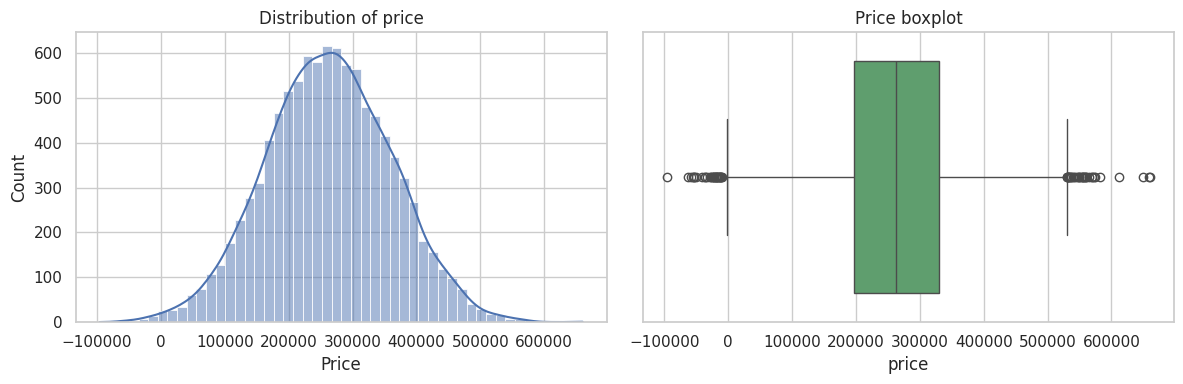

Skewness: 0.009   Kurtosis: -0.024
Prices <= 0: 38


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of price")
axes[0].set_xlabel("Price")
sns.boxplot(x=df[TARGET], ax=axes[1], color="#55A868")
axes[1].set_title("Price boxplot")
plt.tight_layout()
plt.show()

print(f"Skewness: {df[TARGET].skew():.3f}   Kurtosis: {df[TARGET].kurt():.3f}")
print(f"Prices <= 0: {(df[TARGET] <= 0).sum()}")

**Reading the plots:** the target is roughly bell-shaped with skewness close to zero, so no log-transform is needed for linear regression. The left tail dips below zero, which is impossible for a real sale price. That is investigated next, before any modelling.

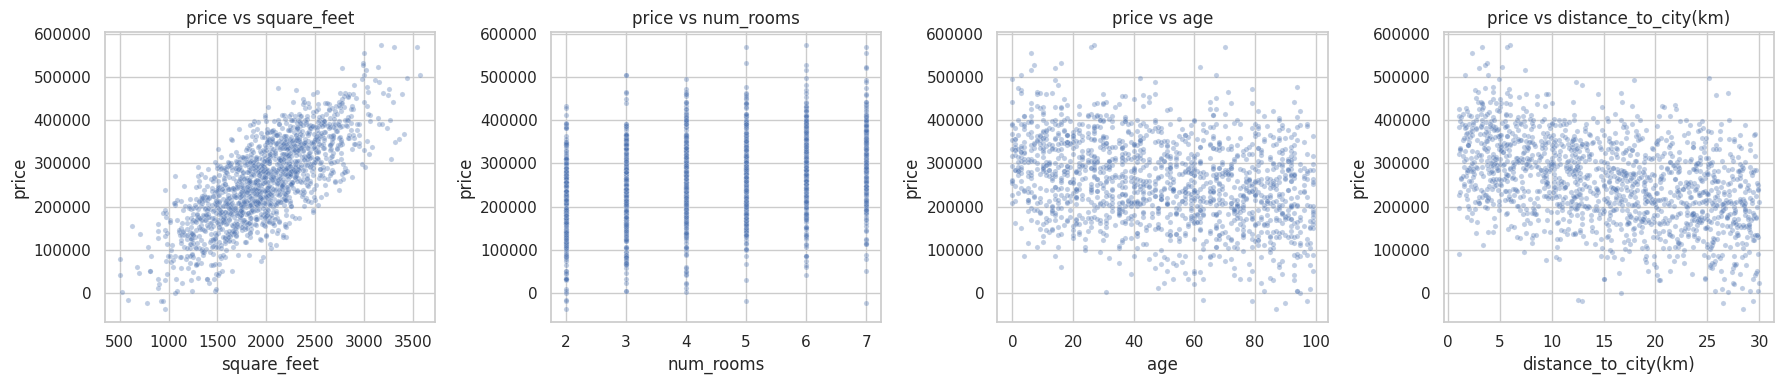

In [6]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(18, 4))
sample = df.sample(1500, random_state=RANDOM_STATE)
for ax, col in zip(axes, FEATURES):
    sns.scatterplot(data=sample, x=col, y=TARGET, alpha=0.35, s=14, ax=ax)
    ax.set_title(f"price vs {col}")
plt.tight_layout()
plt.show()

## 2. Invalid prices: investigate, then set an explicit modelling policy

A sale price must be greater than zero. Rows with `price <= 0` are therefore **invalid target values**, not merely extreme ones. First, how many are there and what do they look like?

In [7]:
neg_mask = df[TARGET] <= 0
print(f"Rows with price <= 0: {neg_mask.sum()} of {len(df):,} ({neg_mask.mean():.2%})")
print(f"   exactly zero: {(df[TARGET] == 0).sum()}   negative: {(df[TARGET] < 0).sum()}")
display(df.loc[neg_mask, TARGET].describe().round(0).to_frame("price of invalid rows"))

profile = pd.DataFrame({
    "invalid rows (price <= 0)": df.loc[neg_mask, FEATURES].mean(),
    "valid rows (price > 0)": df.loc[~neg_mask, FEATURES].mean(),
})
profile["invalid / valid"] = profile.iloc[:, 0] / profile.iloc[:, 1]
print("\nAverage feature values:")
display(profile.round(2))

Rows with price <= 0: 38 of 10,000 (0.38%)
   exactly zero: 0   negative: 38


,price of invalid rows
count,38.0
mean,-25112.0
std,21276.0
min,-95613.0
25%,-35691.0
50%,-19069.0
75%,-11613.0
max,-175.0



Average feature values:


,invalid rows (price <= 0),valid rows (price > 0),invalid / valid
square_feet,865.78,2003.47,0.43
num_rooms,2.74,4.50,0.61
age,70.45,49.44,1.42
distance_to_city(km),24.44,15.33,1.59


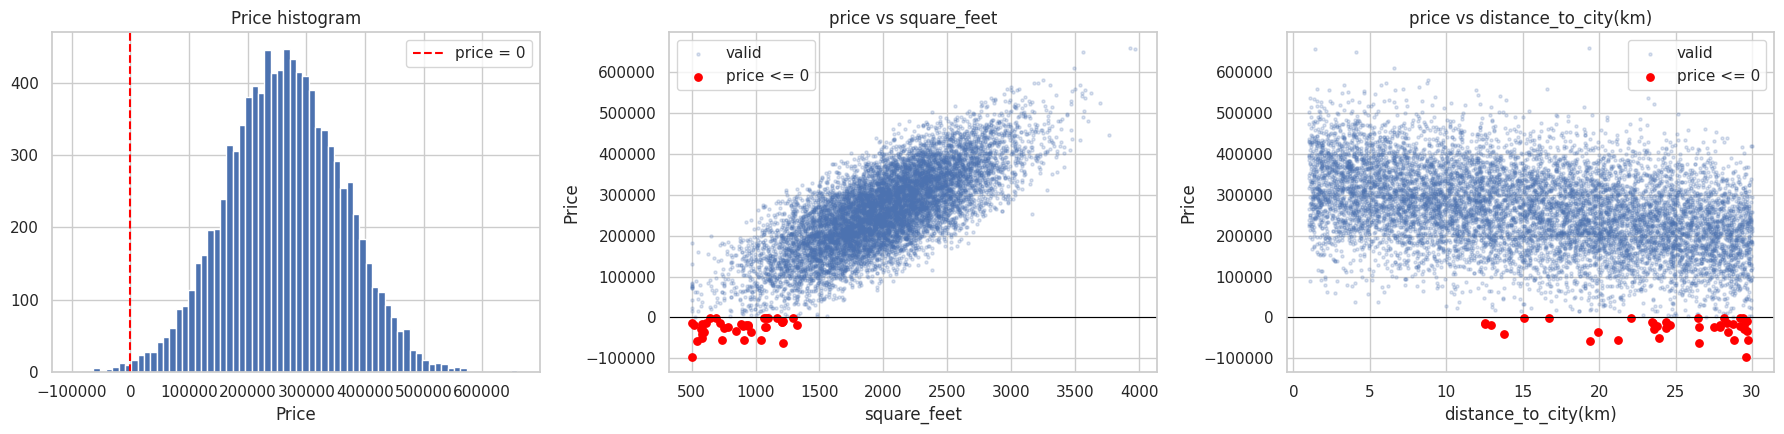

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(df[TARGET], bins=70, color="#4C72B0")
axes[0].axvline(0, color="red", ls="--", label="price = 0")
axes[0].set(title="Price histogram", xlabel="Price"); axes[0].legend()

for ax, col in zip(axes[1:], ["square_feet", "distance_to_city(km)"]):
    ax.scatter(df.loc[~neg_mask, col], df.loc[~neg_mask, TARGET], s=5, alpha=0.2, color="#4C72B0", label="valid")
    ax.scatter(df.loc[neg_mask, col], df.loc[neg_mask, TARGET], s=28, color="red", label="price <= 0")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(title=f"price vs {col}", xlabel=col, ylabel="Price"); ax.legend()
plt.tight_layout()
plt.show()

**Where do they come from?** The invalid rows are not scattered at random: they are **small, old, far-from-centre houses** (on average about 870 sq ft and 2.7 rooms versus about 2,000 sq ft and 4.5 rooms for valid rows; about 70 years old versus 49; about 24 km from the centre versus 15). That is exactly the corner of the data where the price should be lowest. The next cell checks whether the *underlying linear trend* is already near zero there.

In [9]:
# DIAGNOSTIC ONLY: a trend line through all rows, used to understand the invalid rows.
# Nothing from this fit is used by the models below (except the simple rule price > 0).
trend = LinearRegression().fit(df[FEATURES], df[TARGET])
trend_price = pd.Series(trend.predict(df[FEATURES]), index=df.index)
noise_sd = (df[TARGET] - trend_price).std()

diag = pd.Series({
    "Noise around the trend line (residual SD)": round(noise_sd),
    "Rows whose trend-line price is below 0": int((trend_price < 0).sum()),
    "   ...of which have an invalid (<= 0) price": int(((trend_price < 0) & neg_mask).sum()),
    "Invalid rows whose trend-line price is >= 0": int(((trend_price >= 0) & neg_mask).sum()),
    "Highest trend-line price among invalid rows": round(trend_price[neg_mask].max()),
    "Rows with trend-line price below 2 noise SDs": int((trend_price < 2 * noise_sd).sum()),
    "   ...of which are invalid": int(((trend_price < 2 * noise_sd) & neg_mask).sum()),
}, name="value")
display(diag.to_frame())

,value
Noise around the trend line (residual SD),20066
Rows whose trend-line price is below 0,34
...of which have an invalid (<= 0) price,23
Invalid rows whose trend-line price is >= 0,15
Highest trend-line price among invalid rows,37058
Rows with trend-line price below 2 noise SDs,104
...of which are invalid,38


**Interpretation.** A straight line through the data already predicts a *negative* price for 34 small, old, distant houses: 23 of them have an invalid price, and for the other 11 the noise happened to push the price back above zero. The remaining 15 invalid rows have a trend-line price between 0 and about 37,000, within two noise standard deviations (≈ 40,000) of zero, so noise of about 20,000 is enough to push them below it. In fact all 38 invalid rows sit inside that low-price zone. The negative values are therefore consistent with a linear price formula that extrapolates below zero at the extreme low corner, plus random noise on top. The recovered coefficients (Section 12) are also close to round numbers, which suggests the dataset is generated rather than collected. I cannot prove the origin from the file alone; in a real project I would go back to the data source.

### Modelling policy (explicit)
| | Rule |
|---|---|
| **Validity rule** | A price must be `> 0`. This is a fixed rule, not a statistic learned from data, so applying it before the train/test split does not leak information. |
| **Primary model** | Trained **and** evaluated on valid rows only (`price > 0`). |
| **Sensitivity model** | Same train/test split, but the invalid rows are **added to the training set only**. Both models are scored on the **identical positive-price test rows** (Section 9). |
| **Scope** | The excluded rows are the extreme low corner of the feature space, so the primary model is best supported for houses that are not tiny, old *and* far away at once. |

In [10]:
df_valid = df.loc[~neg_mask].reset_index(drop=True)
df_invalid = df.loc[neg_mask].reset_index(drop=True)
print(f"Valid rows used for the primary model: {len(df_valid):,}")
print(f"Invalid rows held out (used only in the Section 9 sensitivity model): {len(df_invalid)}")

Valid rows used for the primary model: 9,962
Invalid rows held out (used only in the Section 9 sensitivity model): 38


## 3. Feature selection discussion

| Feature | Expected relationship with price | Reasoning |
|---|---|---|
| `square_feet` | **Strong positive** | Floor area is the most fundamental driver of value: more space, higher price. |
| `num_rooms` | **Positive** | More rooms generally means a larger, more usable home. It overlaps partly with area, but should add its own signal at a fixed area. |
| `age` | **Negative** | Older houses tend to have depreciation and higher maintenance costs. |
| `distance_to_city(km)` | **Negative** | Proximity to the city centre (jobs, amenities, transport) commands a premium; this is the dataset's proxy for *location*. |

All four features are plausible predictors and none is an identifier, so **all four are kept**. This choice comes from domain reasoning rather than from test-set results. A key check for a linear model is multicollinearity: if two predictors were highly correlated, their coefficients would be unstable. The correlation heatmap and VIF check in Section 5 verify this.

## 4. Missing values and categorical encoding: a leakage-safe pipeline

Imputation and One-Hot Encoding both **learn something from data** (a median, a set of categories). If that learning used the whole dataset, information from the test rows would leak into training. The fix is to put these steps inside a `Pipeline`: calling `.fit()` on the training rows learns the statistics, and `.predict()` on new rows only *applies* them.

For this dataset:
- **Missing values:** none (checked in Section 1), so the median imputer changes nothing for the main model.
- **Categorical columns:** none, so the encoding branch is not used by the main model. One-Hot Encoding is demonstrated on a real categorical feature (a location zone) in **Section 14**, using the same pipeline builder.

In [11]:
def make_preprocessor(numeric_cols, categorical_cols=(), scale=False, categories="auto"):
    """Build an UNFITTED preprocessor.

    numeric:      median imputation (+ optional standardization)
    categorical:  most-frequent imputation + one-hot encoding (first level dropped as the reference)
    Nothing is learned here; statistics are learned when .fit() is called on the TRAINING rows only.
    """
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(numeric_steps), list(numeric_cols))]
    if len(categorical_cols) > 0:
        transformers.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(categories=categories, drop="first",
                                     handle_unknown="ignore", sparse_output=False)),
        ]), list(categorical_cols)))
    return ColumnTransformer(transformers)

make_preprocessor(FEATURES)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_na

## 5. Correlation heatmap

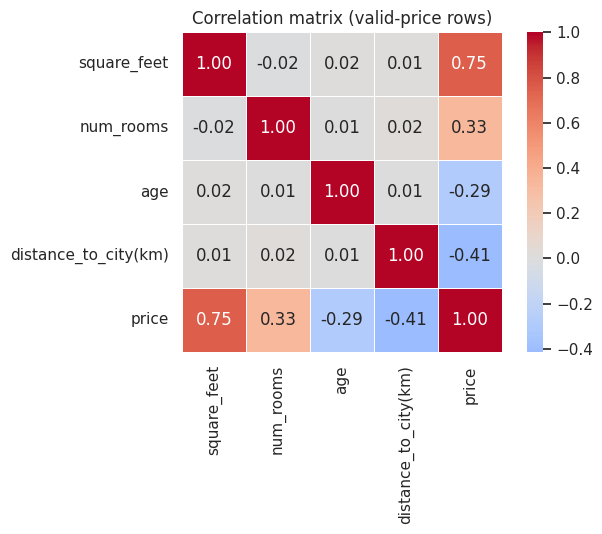

Correlation with price (sorted by strength):
square_feet             0.751
distance_to_city(km)   -0.414
num_rooms               0.330
age                    -0.288
Name: price, dtype: float64


In [12]:
corr = df_valid.corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation matrix (valid-price rows)")
plt.tight_layout()
plt.show()

print("Correlation with price (sorted by strength):")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

In [13]:
# Multicollinearity check: Variance Inflation Factor (about 1 = no problem; above 5-10 = concern)
Xv = df_valid[FEATURES].astype(float)
vif = {}
for col in FEATURES:
    others = Xv.drop(columns=col)
    vif[col] = 1 / (1 - LinearRegression().fit(others, Xv[col]).score(others, Xv[col]))
pd.Series(vif, name="VIF").round(3)

square_feet             1.001
num_rooms               1.001
age                     1.000
distance_to_city(km)    1.001
Name: VIF, dtype: float64

**Interpretation:** `square_feet` has the strongest correlation with price, followed by `distance_to_city(km)` (negative), `num_rooms` (positive) and `age` (negative). The predictors are essentially uncorrelated with one another and the VIFs are about 1, so there is no multicollinearity and the coefficients will be stable. This is descriptive EDA on valid rows; all four features are kept regardless of the result, so no test-set information influences the model.

## 6. Train/test split (80/20)

In [14]:
X = df_valid[FEATURES]
y = df_valid[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows (all valid, price > 0)")

Train: 7,969 rows | Test: 1,993 rows (all valid, price > 0)


## 7. Train the Linear Regression model (pipeline)

In [15]:
lin_reg = Pipeline([
    ("prep", make_preprocessor(FEATURES)),
    ("model", LinearRegression()),
])
lin_reg.fit(X_train, y_train)          # imputation statistics are learned from X_train only

pred_train = lin_reg.predict(X_train)
pred_test = lin_reg.predict(X_test)
print("Pipeline fitted on", len(X_train), "training rows.")

Pipeline fitted on 7969 training rows.


**Check that the pipeline learned from the training rows only.** The imputer's stored medians must match the *training* medians, not the test medians. The second cell injects missing values into a few test rows and shows that they are filled with the training medians.

In [16]:
imputer = lin_reg.named_steps["prep"].named_transformers_["num"].named_steps["impute"]
display(pd.DataFrame({
    "median learned by pipeline (train)": imputer.statistics_,
    "train median": X_train.median().values,
    "test median (never used)": X_test.median().values,
}, index=FEATURES).round(2))

X_demo = X_test.head(5).copy()
X_demo.iloc[0, 0] = np.nan     # square_feet of the first row
X_demo.iloc[1, 2] = np.nan     # age of the second row
filled = pd.DataFrame(lin_reg.named_steps["prep"].transform(X_demo), columns=FEATURES, index=X_demo.index)

assert np.isclose(filled.iloc[0, 0], imputer.statistics_[0])
assert np.isclose(filled.iloc[1, 2], imputer.statistics_[2])
print("\nTest rows with injected missing values:")
display(X_demo.round(2))
print("After the fitted pipeline (blanks filled with TRAIN medians):")
display(filled.round(2))

,median learned by pipeline (train),train median,test median (never used)
square_feet,2004.39,2004.39,1986.35
num_rooms,5.00,5.00,4.00
age,50.00,50.00,49.00
distance_to_city(km),15.32,15.32,15.46



Test rows with injected missing values:


,square_feet,num_rooms,age,distance_to_city(km)
6448,NaN,5,51.0,11.43
6831,2449.26,4,NaN,12.37
8451,2378.59,7,39.0,1.04
39,2098.43,3,80.0,6.48
7458,2404.29,5,26.0,29.57


After the fitted pipeline (blanks filled with TRAIN medians):


,square_feet,num_rooms,age,distance_to_city(km)
6448,2004.39,5.0,51.0,11.43
6831,2449.26,4.0,50.0,12.37
8451,2378.59,7.0,39.0,1.04
39,2098.43,3.0,80.0,6.48
7458,2404.29,5.0,26.0,29.57


## 8. Evaluate: MSE, RMSE, R²

In [17]:
def evaluate(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_true, y_hat), "R2": r2_score(y_true, y_hat)}

results = pd.DataFrame({"Train": evaluate(y_train, pred_train), "Test": evaluate(y_test, pred_test)})
display(results.round(4))
print(f"\nTest RMSE is about {evaluate(y_test, pred_test)['RMSE'] / y_test.mean():.1%} of the mean test price.")

,Train,Test
MSE,3.991153e+08,4.082959e+08
RMSE,1.997787e+04,2.020633e+04
MAE,1.593563e+04,1.626291e+04
R2,9.578000e-01,9.551000e-01



Test RMSE is about 7.7% of the mean test price.


**How to read these:** MSE is in squared price units (hard to interpret directly). **RMSE is in the same units as price**, so it says "the model's typical prediction error is roughly this many price units"; MAE is the plain average miss. **R²** is the share of price variance the model explains. Train and test scores are close, so the model is **not overfitting**.

## 9. Sensitivity check: does including the invalid rows change anything?

Same split, same test rows. The only difference is that the alternative model's **training** set also contains the 38 invalid rows. Both are scored on the identical `X_test` / `y_test`, which contain valid prices only, so the comparison is fair.

In [18]:
X_train_alt = pd.concat([X_train, df_invalid[FEATURES]], ignore_index=True)
y_train_alt = pd.concat([y_train, df_invalid[TARGET]], ignore_index=True)

lin_reg_alt = Pipeline([("prep", make_preprocessor(FEATURES)), ("model", LinearRegression())])
lin_reg_alt.fit(X_train_alt, y_train_alt)
pred_test_alt = lin_reg_alt.predict(X_test)          # same X_test as the primary model

print(f"Training rows: primary {len(X_train):,} | alternative {len(X_train_alt):,}")
print(f"Test rows (identical for both): {len(X_test):,}\n")

sens = pd.DataFrame({
    "Primary (invalid rows excluded)": evaluate(y_test, pred_test),
    "Alternative (invalid rows in training)": evaluate(y_test, pred_test_alt),
})
display(sens.round(4))

coef_cmp = pd.DataFrame({
    "Primary": np.r_[lin_reg.named_steps["model"].intercept_, lin_reg.named_steps["model"].coef_],
    "Alternative": np.r_[lin_reg_alt.named_steps["model"].intercept_, lin_reg_alt.named_steps["model"].coef_],
}, index=["intercept"] + FEATURES)
coef_cmp["Difference"] = coef_cmp["Alternative"] - coef_cmp["Primary"]
print("Coefficients:")
display(coef_cmp.round(2))

Training rows: primary 7,969 | alternative 8,007
Test rows (identical for both): 1,993



,Primary (invalid rows excluded),Alternative (invalid rows in training)
MSE,4.082959e+08,4.081096e+08
RMSE,2.020633e+04,2.020172e+04
MAE,1.626291e+04,1.626299e+04
R2,9.551000e-01,9.552000e-01


Coefficients:


,Primary,Alternative,Difference
intercept,447.52,-222.47,-669.99
square_feet,149.35,149.68,0.33
num_rooms,20100.37,20139.53,39.16
age,-1001.28,-1003.02,-1.74
distance_to_city(km),-4994.84,-5005.38,-10.54


In [19]:
# Where could excluding the rows matter most? The low-price corner.
low = pred_test <= np.quantile(pred_test, 0.10)       # lowest 10% of predicted prices (primary model)
err = pd.DataFrame({
    "Primary": [(y_test - pred_test).mean(), (y_test[low] - pred_test[low]).mean()],
    "Alternative": [(y_test - pred_test_alt).mean(), (y_test[low] - pred_test_alt[low]).mean()],
}, index=["Mean error, all test rows", "Mean error, lowest-predicted decile"])
display(err.round(1))
print(f"Largest absolute difference between the two models' predictions: {np.abs(pred_test_alt - pred_test).max():,.0f}")
print(f"Typical prediction error (RMSE) for scale: {np.sqrt(mean_squared_error(y_test, pred_test)):,.0f}")

,Primary,Alternative
"Mean error, all test rows",36.4,119.0
"Mean error, lowest-predicted decile",-907.4,-488.2


Largest absolute difference between the two models' predictions: 678
Typical prediction error (RMSE) for scale: 20,206


**Result: the policy choice makes almost no difference to the model.**

- **Accuracy is unchanged.** On the same 1,993 test rows, R² is 0.9551 versus 0.9552, RMSE is 20,206 versus 20,202, and MAE is identical to the nearest unit (16,263).
- **Coefficients barely move.** Every slope changes by about 0.2% (for example, `num_rooms` 20,100 versus 20,140 and `distance_to_city(km)` −4,995 versus −5,005). The intercept shifts by about 670, but it is not interpreted (see Section 12).
- **Predictions are nearly the same.** The largest gap between the two models' predictions on any test house is 678, about 3% of the typical error.
- **The one visible effect is where expected:** in the lowest-predicted-price decile the primary model over-predicts by about 900 on average, versus about 490 for the alternative. That is under 5% of the typical error, and it points the way you would expect, since the excluded rows all lie in that low corner.

**Decision:** keep the exclusion as the primary policy. Invalid prices should not be fitted as if they were real sales, and this check shows the exclusion costs nothing measurable in accuracy.

## 10. Actual vs. predicted prices

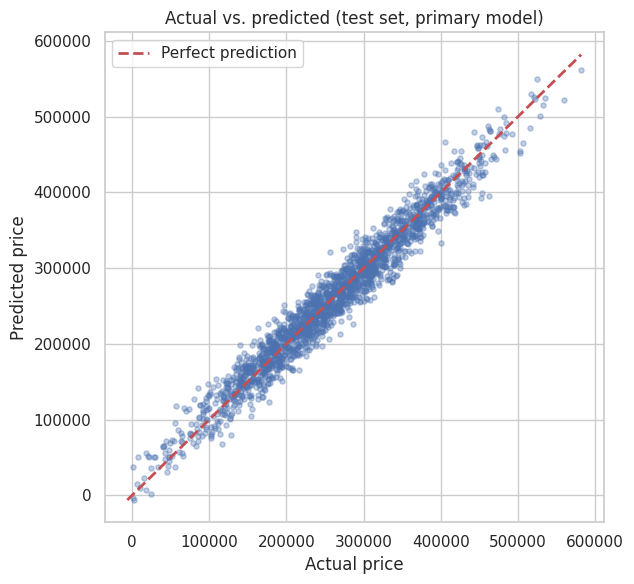

In [20]:
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, pred_test, alpha=0.35, s=14, color="#4C72B0")
lims = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
plt.plot(lims, lims, "r--", lw=2, label="Perfect prediction")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs. predicted (test set, primary model)")
plt.legend()
plt.tight_layout()
plt.show()

Points hug the red diagonal across the full price range with no visible curvature, so the linear model captures the relationship well. The spread around the line reflects noise the four features cannot explain.

## 11. Residual analysis

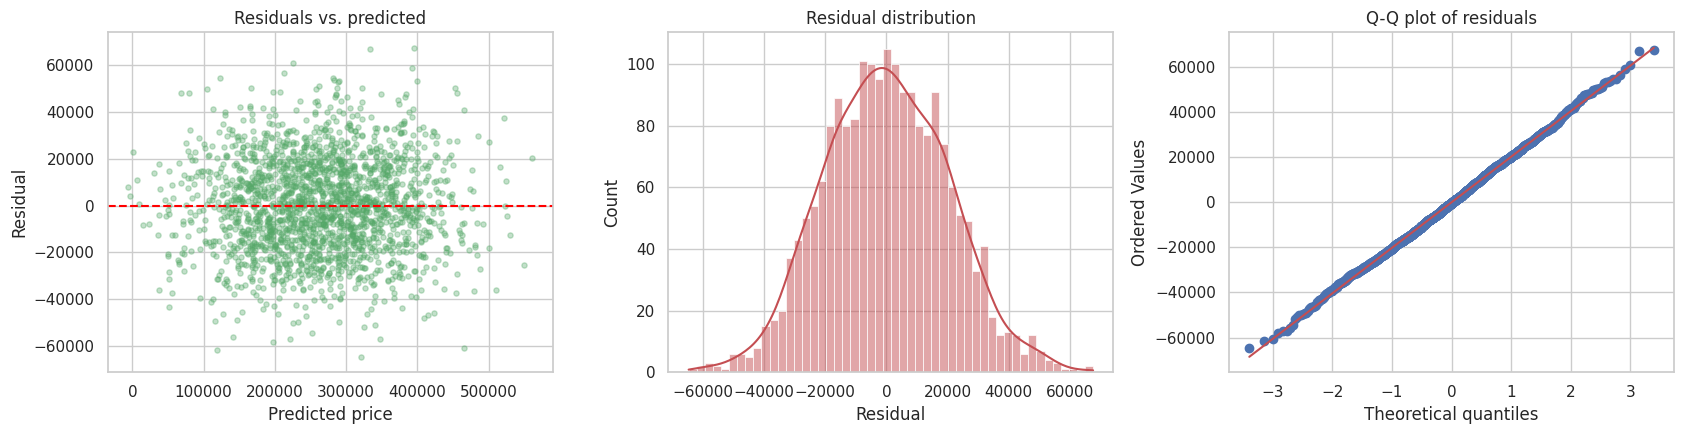

Mean residual: 36.4   SD: 20211.4   Skew: 0.067   Excess kurtosis: -0.093

Residuals by predicted-price quintile:
            mean      std
lowest    -941.0  20193.0
low-mid  -1060.0  19841.0
middle    1358.0  20266.0
high-mid  -248.0  20097.0
highest   1069.0  20627.0


In [21]:
residuals = y_test - pred_test

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(pred_test, residuals, alpha=0.35, s=14, color="#55A868")
axes[0].axhline(0, color="red", ls="--")
axes[0].set(xlabel="Predicted price", ylabel="Residual", title="Residuals vs. predicted")
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color="#C44E52")
axes[1].set(xlabel="Residual", title="Residual distribution")
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q plot of residuals")
plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():.1f}   SD: {residuals.std():.1f}   Skew: {stats.skew(residuals):.3f}   Excess kurtosis: {stats.kurtosis(residuals):.3f}")
quint = pd.qcut(pred_test, 5, labels=["lowest", "low-mid", "middle", "high-mid", "highest"])
print("\nResiduals by predicted-price quintile:")
print(residuals.groupby(quint, observed=True).agg(["mean", "std"]).round(0).to_string())

**What we look for:** (1) residuals scattered randomly around zero with no funnel or curve, meaning linearity and constant variance (homoscedasticity) hold; (2) a bell-shaped residual histogram and a straight Q-Q line, meaning the errors are approximately normal.

Both hold here. The mean residual is about 36 against an SD of about 20,200, skewness is 0.07 and excess kurtosis is −0.09, so the distribution is close to normal. The residual SD is about the same in every predicted-price quintile (19,800 to 20,600), so there is no funnel. The quintile means (within about ±1,400) show no trend, and with roughly 400 houses per quintile their standard error is about 1,000, so they are consistent with zero. Linear regression is an appropriate model for this data.

## 12. Coefficient analysis

Two different tables answer two different questions, so they are kept separate.

* **Raw coefficients** answer: *by how much does price change when this feature rises by one of its own units, holding the other features fixed?* They are in price units per unit of the feature.
* **Standardized coefficients** answer: *which features matter most?* Each raw coefficient is multiplied by that feature's standard deviation, giving the price change for a **+1 standard deviation** move. Only then are features on a comparable scale.

In [22]:
model = lin_reg.named_steps["model"]
units = {"square_feet": "+1 sq ft", "num_rooms": "+1 room", "age": "+1 year of age", "distance_to_city(km)": "+1 km from centre"}

raw = pd.DataFrame({
    "Change in feature": [units[f] for f in FEATURES],
    "Raw coefficient (price change)": model.coef_,
}, index=FEATURES)
display(raw.round(2))
print(f"Intercept: {model.intercept_:,.1f}  (price of a hypothetical house with every feature at 0: not meaningful, so not interpreted)")

,Change in feature,Raw coefficient (price change)
square_feet,+1 sq ft,149.35
num_rooms,+1 room,20100.37
age,+1 year of age,-1001.28
distance_to_city(km),+1 km from centre,-4994.84


Intercept: 447.5  (price of a hypothetical house with every feature at 0: not meaningful, so not interpreted)


In [23]:
# Standardized coefficient = raw coefficient x feature SD (training rows; ddof=0 matches StandardScaler).
sd = X_train.std(ddof=0)
std_coef = pd.Series(model.coef_, index=FEATURES) * sd

std_table = pd.DataFrame({
    "Feature SD (own units)": sd,
    "Standardized coefficient (price change per +1 SD)": std_coef,
    "Rank by |influence|": std_coef.abs().rank(ascending=False).astype(int),
}).sort_values("Rank by |influence|")
display(std_table.round(2))

# Verification: refit on genuinely standardized features and compare.
scaled_check = Pipeline([("prep", make_preprocessor(FEATURES, scale=True)), ("model", LinearRegression())]).fit(X_train, y_train)
print("Scaled-pipeline coefficients match raw x SD:", np.allclose(scaled_check.named_steps["model"].coef_, std_coef.values))
print("Scaled-pipeline predictions match unscaled predictions:", np.allclose(scaled_check.predict(X_test), pred_test))

,Feature SD (own units),Standardized coefficient (price change per +1 SD),Rank by |influence|
square_feet,497.34,74279.15,1
distance_to_city(km),8.30,-41433.75,2
num_rooms,1.71,34454.17,3
age,29.03,-29068.19,4


Scaled-pipeline coefficients match raw x SD: True
Scaled-pipeline predictions match unscaled predictions: True


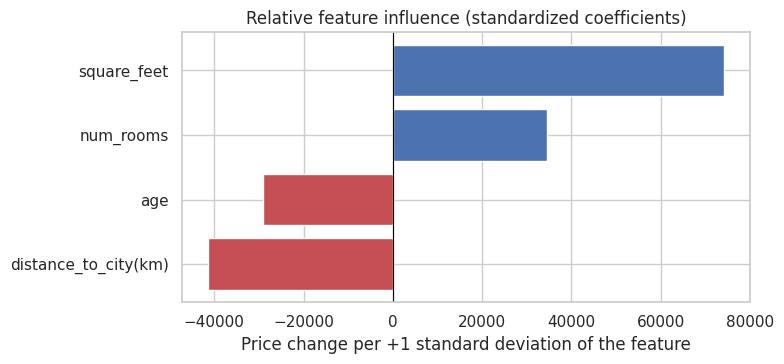

In [24]:
order = std_coef.sort_values()
plt.figure(figsize=(8, 3.8))
plt.barh(order.index, order.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in order.values])
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Price change per +1 standard deviation of the feature")
plt.title("Relative feature influence (standardized coefficients)")
plt.tight_layout()
plt.show()

In [25]:
for f in FEATURES:
    c = model.coef_[FEATURES.index(f)]
    print(f"{units[f]:<20} -> price {'rises' if c > 0 else 'falls'} by about {abs(c):>9,.0f}   (other features fixed)")

+1 sq ft             -> price rises by about       149   (other features fixed)
+1 room              -> price rises by about    20,100   (other features fixed)
+1 year of age       -> price falls by about     1,001   (other features fixed)
+1 km from centre    -> price falls by about     4,995   (other features fixed)


**Reading the raw coefficients (price change per unit).** Holding the other features fixed: each extra square foot adds about 149; each extra room adds about 20,100 (at the same floor area); each extra year of age subtracts about 1,001; and each extra kilometre from the city centre subtracts about 4,995. These are the numbers to use for explanations and for "what if" estimates in real units (for example, +100 sq ft ≈ +14,900).

**Why they cannot be ranked.** The units differ, so raw magnitudes are not comparable. A room's coefficient (20,100) is about 135 times a square foot's (149), which could wrongly suggest rooms matter far more than area. But a typical house varies by only about 1.7 rooms (one SD) while its area varies by about 497 sq ft.

**Reading the standardized coefficients (influence per +1 SD).** On a common scale the order is: `square_feet` (+74,279 per 497 sq ft) is the most influential feature and the strongest positive driver; `distance_to_city(km)` (−41,434 per 8.3 km) is the strongest negative driver; `num_rooms` (+34,454 per 1.7 rooms) is third; and `age` (−29,068 per 29 years) is fourth. The check cell confirms that refitting on standardized features reproduces these values exactly and gives identical predictions, so scaling changes the presentation of the coefficients, not the model.

**Caveats.** These are associations in this dataset, not causal effects. Standardized values depend on how widely each feature varies in the sample. Because the VIFs are about 1, no feature is sharing credit with a correlated one, which is why the coefficients are stable. The `num_rooms` effect is the extra price of a room *at a fixed floor area*.

## 13. (Bonus) Linear vs. Ridge vs. Lasso

In [26]:
alphas = np.logspace(-3, 3, 50)
# Regularization penalizes coefficient size, so the features must be standardized (learned on training rows only, inside the pipeline).
models = {
    "Linear": LinearRegression(),
    "Ridge": RidgeCV(alphas=alphas),
    "Lasso": LassoCV(alphas=alphas, cv=5, random_state=RANDOM_STATE, max_iter=20000),
}
fitted = {}
rows = []
for name, est in models.items():
    pipe = Pipeline([("prep", make_preprocessor(FEATURES, scale=True)), ("model", est)]).fit(X_train, y_train)
    fitted[name] = pipe
    rows.append({"Model": name, "alpha": getattr(est, "alpha_", np.nan), **evaluate(y_test, pipe.predict(X_test))})
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison.round(4))

coef_std_cmp = pd.DataFrame({n: p.named_steps["model"].coef_ for n, p in fitted.items()}, index=FEATURES)
print("Coefficients on standardized features (price change per +1 SD):")
display(coef_std_cmp.round(0))

,alpha,MSE,RMSE,MAE,R2
Model,,,,,
Linear,NaN,4.082959e+08,20206.3326,16262.9134,0.9551
Ridge,0.1600,4.082980e+08,20206.3844,16262.9039,0.9551
Lasso,8.2864,4.083053e+08,20206.5659,16262.6920,0.9551


Coefficients on standardized features (price change per +1 SD):


,Linear,Ridge,Lasso
square_feet,74279.0,74278.0,74271.0
num_rooms,34454.0,34453.0,34446.0
age,-29068.0,-29068.0,-29060.0
distance_to_city(km),-41434.0,-41433.0,-41425.0


**Takeaway:** all three models give practically identical test scores and almost identical coefficients. That is expected: with four uncorrelated predictors and about 8,000 training rows, ordinary least squares already has low variance, so there is little for regularization to fix. Lasso does not zero out any feature because every feature carries real signal. Regularization would matter more with many features, correlated features or small samples. Plain Linear Regression is the simplest and most interpretable, and it performs as well, so it remains the final choice.

## 14. Extension: One-Hot Encoding on a real categorical feature

The raw data has no categorical column, so here One-Hot Encoding is demonstrated on a *derived* one: a **location zone** built from `distance_to_city(km)` with fixed cut-offs (Urban under 10 km, Suburban 10 to 20 km, Rural 20 km or more). The cut-offs are chosen by hand, not learned from data, so creating the zone before the split does not leak. The **encoder itself is fitted inside the pipeline on the training rows only**, using the same split and the same test rows as the main model. This is a demonstration, not a replacement; binning throws away information, so a lower score than the continuous-distance model is expected.

In [27]:
ZONES = ["Urban", "Suburban", "Rural"]
df_zone = df_valid.copy()
df_zone["location_zone"] = pd.cut(df_zone["distance_to_city(km)"], bins=[0, 10, 20, np.inf],
                                  labels=ZONES, right=False).astype(str)
print(df_zone["location_zone"].value_counts().reindex(ZONES))

ZONE_NUMERIC = ["square_feet", "num_rooms", "age"]
ZONE_CATEGORICAL = ["location_zone"]
Z_train = df_zone.loc[X_train.index, ZONE_NUMERIC + ZONE_CATEGORICAL]   # same training rows as the main model
Z_test = df_zone.loc[X_test.index, ZONE_NUMERIC + ZONE_CATEGORICAL]     # same test rows as the main model

zone_model = Pipeline([
    ("prep", make_preprocessor(ZONE_NUMERIC, ZONE_CATEGORICAL, categories=[ZONES])),
    ("model", LinearRegression()),
]).fit(Z_train, y_train)

encoder = zone_model.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
print("\nCategories learned by the encoder (first = reference level, dropped):", list(encoder.categories_[0]))

names = [n.split("__", 1)[1] for n in zone_model.named_steps["prep"].get_feature_names_out()]
print("\nEncoded design matrix, first 5 test rows:")
display(pd.DataFrame(zone_model.named_steps["prep"].transform(Z_test.head()), columns=names).round(2))

location_zone
Urban       3153
Suburban    3455
Rural       3354
Name: count, dtype: int64

Categories learned by the encoder (first = reference level, dropped): ['Urban', 'Suburban', 'Rural']

Encoded design matrix, first 5 test rows:


,square_feet,num_rooms,age,location_zone_Suburban,location_zone_Rural
0,1085.16,5.0,51.0,1.0,0.0
1,2449.26,4.0,66.0,1.0,0.0
2,2378.59,7.0,39.0,0.0,0.0
3,2098.43,3.0,80.0,0.0,0.0
4,2404.29,5.0,26.0,0.0,1.0


In [28]:
zone_results = pd.DataFrame({
    "Continuous distance (main model)": evaluate(y_test, pred_test),
    "Location zone, one-hot encoded": evaluate(y_test, zone_model.predict(Z_test)),
})
display(zone_results.round(4))

zone_coef = pd.Series(zone_model.named_steps["model"].coef_, index=names, name="coefficient")
display(zone_coef.round(1).to_frame())

,Continuous distance (main model),"Location zone, one-hot encoded"
MSE,4.082959e+08,6.206157e+08
RMSE,2.020633e+04,2.491216e+04
MAE,1.626291e+04,2.006452e+04
R2,9.551000e-01,9.318000e-01


,coefficient
square_feet,149.3
num_rooms,19936.6
age,-1008.7
location_zone_Suburban,-47476.1
location_zone_Rural,-96174.8


**Reading the result.**

- **The encoder learned its categories from the training rows only**, in the order declared. The first level (Urban) is dropped as the reference, so the design matrix has one 0/1 column per remaining zone. The five sample rows match their distances (11.4 km → Suburban, 1.0 km → Urban, 29.6 km → Rural).
- **Coefficients are relative to the reference level.** Holding area, rooms and age fixed, a Suburban house is about 47,500 cheaper than an Urban one, and a Rural house about 96,200 cheaper.
- **The score is lower, as expected.** Test R² is 0.932 versus 0.955 and RMSE is 24,912 versus 20,206 (about 23% higher). Binning treats a house 21 km out the same as one 29 km out, discarding distance information that the continuous feature keeps. The main model keeps continuous distance.

## 15. Summary

**Data:** 10,000 houses, four numeric predictors, no missing values, no duplicates and no categorical columns. 38 rows (0.38%) have negative prices.

**Preprocessing:** Imputation, encoding and scaling live inside scikit-learn pipelines that are fitted on the training rows only. A demonstration shows the fitted pipeline filling injected gaps in test rows with *training* medians. One-Hot Encoding is demonstrated on a derived location zone, with the encoder fitted on the training rows.

**Invalid prices:** The 38 rows are small, old, far-away houses, exactly where a straight-line price formula already reaches zero, so the negatives are consistent with the formula plus noise. **Policy:** exclude them from the primary model (9,962 valid rows; 7,969 train and 1,993 test). **Sensitivity:** adding them to the training set only, and scoring both models on the identical 1,993 positive-price test rows, changes R² from 0.9551 to 0.9552, RMSE from 20,206 to 20,202, and each slope by about 0.2%.

**Model:** Linear Regression on the 80/20 split reaches **test R² ≈ 0.955 and RMSE ≈ 20,200** (about 7.7% of the mean test price; MAE ≈ 16,300). Train R² is 0.958, so there is no overfitting.

**Diagnostics:** Predictions follow the diagonal. Residuals are centred on zero, close to normal (skew 0.07) and have constant spread across predicted-price quintiles. Predictors are uncorrelated (VIF ≈ 1).

**Coefficients:**
- *Raw (per unit, others fixed):* +149 per sq ft, +20,100 per room, −1,001 per year of age, −4,995 per km from the centre. Use these to explain and to estimate in real units; do not rank features by them.
- *Standardized (per +1 SD):* square_feet +74,279, distance_to_city(km) −41,434, num_rooms +34,454, age −29,068. Use these to compare influence: area matters most, then distance, rooms and age.

**Regularization (bonus):** Ridge and Lasso match plain Linear Regression to four decimal places of R², with almost identical coefficients. With four uncorrelated predictors and about 8,000 training rows there is nothing for regularization to fix, so the simplest model is retained.

**Limitations.** The relationships are associations, not causal effects. The model has only four features (no neighbourhood quality, condition and so on). The dataset appears to be generated, and the model is least supported for the extreme low corner (tiny, old and far-away houses) that the excluded rows came from.